# Apéndice: comparación UG vs RG

Este notebook compara la evolución cosmológica del modelo

$
p=-\rho-A\rho^\nu
$

en dos marcos:

- **Relatividad General (RG):** $(Q=0)$.
- **Gravedad Unimodular (UG):** $(Q=\alpha\rho)$, con $(\alpha)$ fijo.

La convención gráfica está diseñada para la defensa:

- **línea continua:** UG,
- **línea discontinua:** RG,
- **color:** valor de $(\nu)$.

Cada intervalo se representa mediante una figura con cuatro paneles:

$
\rho(t),\qquad a(t),\qquad H(t),\qquad \dot H(t).
$

Se estudian los cinco casos utilizados en la tesis:

$
\nu<0,\qquad \nu=0,\qquad 0<\nu<\frac12,
\qquad \frac12<\nu<1,\qquad \nu>1.
$

Para los intervalos abiertos se usan cuatro valores de $(\nu)$. El caso $(\nu=0)$ es un valor aislado, por lo que allí se compara una única curva UG con una única curva RG.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

CURRENT_PATH = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in (CURRENT_PATH, *CURRENT_PATH.parents)
        if (candidate / "src").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("No se encontró la raíz del proyecto.")

FIG_DIR = PROJECT_ROOT.joinpath('results', 'figures', 'ug_vs_rg')
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "legend.fontsize": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
})

print("Carpeta de figuras:", FIG_DIR.relative_to(PROJECT_ROOT))


Carpeta de figuras: results/figures/ug_vs_rg


## 1. Ecuaciones utilizadas

En RG:

$
3H_{\rm RG}^2=\rho_{\rm RG},
\qquad
\dot\rho_{\rm RG}=\sqrt{3}A\rho_{\rm RG}^{\nu+1/2}.
$

En UG, para $(Q=\alpha\rho)$:

$
3H_{\rm UG}^2=(1+\alpha)\rho_{\rm UG},
\qquad
\dot\rho_{\rm UG}=\frac{\sqrt{3}A}{\sqrt{1+\alpha}}
\rho_{\rm UG}^{\nu+1/2}.
$

En ambos marcos,

$
\dot H=\frac{A}{2}\rho^\nu,
$

pero $(\dot H_{\rm UG}(t))$ y $(\dot H_{\rm RG}(t))$ pueden diferir porque las densidades evolucionan de manera distinta.

Para $(\nu>1/2)$, el tiempo singular es

$
t_s-t_0=
\frac{\rho_0^{1/2-\nu}\sqrt{1+\alpha}}
{\sqrt{3}A(\nu-1/2)}
$

en UG, mientras que RG se recupera tomando $(\alpha=0)$.

In [2]:
def _validate_parameters(A, alpha, rho0, a0=1.0):
    if A <= 0:
        raise ValueError("Se requiere A > 0.")
    if alpha <= -1:
        raise ValueError("Se requiere alpha > -1 para UG.")
    if rho0 <= 0:
        raise ValueError("Se requiere rho0 > 0.")
    if a0 <= 0:
        raise ValueError("Se requiere a0 > 0.")


def rho_of_t(t, A, nu, alpha, rho0=1.0, t0=0.0):
    """Densidad analítica. RG corresponde a alpha=0; UG a alpha != 0."""
    _validate_parameters(A=A, alpha=alpha, rho0=rho0)

    t = np.asarray(t, dtype=float)
    k = np.sqrt(3.0) * A / np.sqrt(1.0 + alpha)

    if np.isclose(nu, 0.5):
        return rho0 * np.exp(k * (t - t0))

    m = 0.5 - nu
    bracket = rho0**m + m * k * (t - t0)

    rho = np.full_like(t, np.nan, dtype=float)
    valid = bracket > 0.0
    rho[valid] = bracket[valid] ** (1.0 / m)
    return rho


def log_a_from_rho(rho, A, nu, alpha, rho0=1.0, a0=1.0):
    """ln(a) para evitar overflow. RG = alpha=0; UG = alpha_UG."""
    _validate_parameters(A=A, alpha=alpha, rho0=rho0, a0=a0)
    rho = np.asarray(rho, dtype=float)
    log_a0 = np.log(a0)

    if np.isclose(nu, 1.0):
        return log_a0 + (1.0 + alpha) / (3.0 * A) * np.log(rho / rho0)

    exponent = (
        (1.0 + alpha)
        / (3.0 * A * (1.0 - nu))
        * (rho ** (1.0 - nu) - rho0 ** (1.0 - nu))
    )
    return log_a0 + exponent


def a_from_rho(rho, A, nu, alpha, rho0=1.0, a0=1.0):
    log_a = log_a_from_rho(
        rho=rho,
        A=A,
        nu=nu,
        alpha=alpha,
        rho0=rho0,
        a0=a0,
    )
    # Evita overflow de exp sin alterar la región físicamente útil del gráfico.
    return np.exp(np.clip(log_a, -700.0, 700.0))


def H_from_rho(rho, alpha):
    rho = np.asarray(rho, dtype=float)
    return np.sqrt((1.0 + alpha) * rho / 3.0)


def Hdot_from_rho(rho, A, nu):
    rho = np.asarray(rho, dtype=float)
    return 0.5 * A * rho**nu


def singular_time(A, nu, alpha, rho0=1.0, t0=0.0):
    """Tiempo en que rho diverge. Es infinito para nu <= 1/2."""
    _validate_parameters(A=A, alpha=alpha, rho0=rho0)

    if nu <= 0.5 or np.isclose(nu, 0.5):
        return np.inf

    return (
        t0
        + rho0 ** (0.5 - nu)
        * np.sqrt(1.0 + alpha)
        / (np.sqrt(3.0) * A * (nu - 0.5))
    )


In [3]:
# Comprobaciones analíticas básicas
assert np.isclose(Hdot_from_rho(np.array([1.0]), A=1.0, nu=0.0)[0], 0.5)
assert np.isinf(singular_time(A=1.0, nu=0.4, alpha=0.3))
assert np.isfinite(singular_time(A=1.0, nu=0.75, alpha=0.3))
assert np.isclose(
    singular_time(A=1.0, nu=0.75, alpha=0.0),
    1.0 / (np.sqrt(3.0) * 0.25),
)
print("Comprobaciones analíticas superadas.")

Comprobaciones analíticas superadas.


## 2. Parámetros globales

Para la comparación de la defensa se fija un único valor de difusión en UG:

\[
\alpha_{\rm UG}=0.3.
\]

RG se representa mediante \(\alpha=0\). De esta manera, para cada valor de \(\nu\), la diferencia entre las dos curvas corresponde únicamente al cambio de marco gravitacional/difusivo.

In [4]:
A = 1.0
RHO0 = 1.0
A0 = 1.0
T0 = 0.0

ALPHA_UG = 0.3
ALPHA_RG = 0.0

print("Parámetros:")
print(f"A        = {A}")
print(f"rho0     = {RHO0}")
print(f"a0       = {A0}")
print(f"t0       = {T0}")
print(f"alpha_UG = {ALPHA_UG}")
print(f"alpha_RG = {ALPHA_RG}  (RG)")

Parámetros:
A        = 1.0
rho0     = 1.0
a0       = 1.0
t0       = 0.0
alpha_UG = 0.3
alpha_RG = 0.0  (RG)


## 3. Función de comparación UG–RG

Convención visual:

- cada color representa un valor de \(\nu\),
- línea continua: UG,
- línea discontinua: RG.

Para singularidades de tiempo finito, cada curva se evalúa hasta el 97\% de su propio tiempo singular. Así se conserva visualmente la diferencia entre $(t_s^{\rm UG})$ y $(t_s^{\rm RG})$.

In [5]:
def _nu_colors(nu_values):
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    return {
        nu: colors[i % len(colors)]
        for i, nu in enumerate(nu_values)
    }


def _add_comparison_legends(ax, nu_values, colors):
    nu_handles = [
        Line2D(
            [0], [0],
            color=colors[nu],
            linestyle="-",
            linewidth=2.2,
            label=rf"$\nu={nu:g}$",
        )
        for nu in nu_values
    ]

    theory_handles = [
        Line2D(
            [0], [0],
            color="black",
            linestyle="-",
            linewidth=2.2,
            label=rf"UG ($\alpha={ALPHA_UG:g}$)",
        ),
        Line2D(
            [0], [0],
            color="black",
            linestyle="--",
            linewidth=2.0,
            label="RG",
        ),
    ]

    leg1 = ax.legend(
        handles=nu_handles,
        title=r"Valores de $\nu$",
        loc="upper left",
        fontsize=8,
        title_fontsize=9,
    )
    ax.add_artist(leg1)

    ax.legend(
        handles=theory_handles,
        title="Marco",
        loc="lower right",
        fontsize=8,
        title_fontsize=9,
    )


def _time_grid(A, nu, alpha, rho0, t0, t_max, singular_fraction, n_points):
    ts = singular_time(
        A=A,
        nu=nu,
        alpha=alpha,
        rho0=rho0,
        t0=t0,
    )

    if np.isfinite(ts):
        t_end = t0 + singular_fraction * (ts - t0)
    else:
        t_end = t_max

    return np.linspace(t0, t_end, n_points), ts


def plot_ug_vs_rg_interval(
    nu_values,
    title,
    filename,
    A=1.0,
    rho0=1.0,
    a0=1.0,
    t0=0.0,
    alpha_ug=0.3,
    t_max=10.0,
    singular_fraction=0.97,
    n_points=1400,
    a_log_scale=True,
    use_log_a=False,
):
    """Figura 2x2 con rho, a, H y Hdot comparando UG y RG."""

    colors = _nu_colors(nu_values)

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(13.2, 8.8),
    )
    axes = axes.flatten()

    # Orden intencional: UG primero y RG después.
    # Si ambas curvas coinciden, los trazos RG quedan visibles sobre UG.
    for nu in nu_values:
        color = colors[nu]

        # -------------------------
        # UG: alpha = alpha_ug
        # -------------------------
        t_ug, _ = _time_grid(
            A=A,
            nu=nu,
            alpha=alpha_ug,
            rho0=rho0,
            t0=t0,
            t_max=t_max,
            singular_fraction=singular_fraction,
            n_points=n_points,
        )

        rho_ug = rho_of_t(
            t_ug,
            A=A,
            nu=nu,
            alpha=alpha_ug,
            rho0=rho0,
            t0=t0,
        )
        log_a_ug = log_a_from_rho(
            rho_ug, A=A, nu=nu, alpha=alpha_ug, rho0=rho0, a0=a0
        )
        a_ug = (
            None
            if use_log_a
            else a_from_rho(
                rho_ug, A=A, nu=nu, alpha=alpha_ug, rho0=rho0, a0=a0
            )
        )
        H_ug = H_from_rho(rho_ug, alpha=alpha_ug)
        Hdot_ug = Hdot_from_rho(rho_ug, A=A, nu=nu)

        axes[0].plot(t_ug, rho_ug, color=color, linestyle="-", linewidth=2.1)
        axes[1].plot(
            t_ug, log_a_ug if use_log_a else a_ug,
            color=color, linestyle="-", linewidth=2.1,
        )
        axes[2].plot(t_ug, H_ug, color=color, linestyle="-", linewidth=2.1)
        axes[3].plot(t_ug, Hdot_ug, color=color, linestyle="-", linewidth=2.1)

        # -------------------------
        # RG: alpha = 0
        # -------------------------
        t_rg, _ = _time_grid(
            A=A,
            nu=nu,
            alpha=0.0,
            rho0=rho0,
            t0=t0,
            t_max=t_max,
            singular_fraction=singular_fraction,
            n_points=n_points,
        )

        rho_rg = rho_of_t(
            t_rg,
            A=A,
            nu=nu,
            alpha=0.0,
            rho0=rho0,
            t0=t0,
        )
        log_a_rg = log_a_from_rho(
            rho_rg, A=A, nu=nu, alpha=0.0, rho0=rho0, a0=a0
        )
        a_rg = (
            None
            if use_log_a
            else a_from_rho(
                rho_rg, A=A, nu=nu, alpha=0.0, rho0=rho0, a0=a0
            )
        )
        H_rg = H_from_rho(rho_rg, alpha=0.0)
        Hdot_rg = Hdot_from_rho(rho_rg, A=A, nu=nu)

        axes[0].plot(t_rg, rho_rg, color=color, linestyle="--", linewidth=1.9)
        axes[1].plot(
            t_rg, log_a_rg if use_log_a else a_rg,
            color=color, linestyle="--", linewidth=1.9,
        )
        axes[2].plot(t_rg, H_rg, color=color, linestyle="--", linewidth=1.9)
        axes[3].plot(t_rg, Hdot_rg, color=color, linestyle="--", linewidth=1.9)

    axes[0].set_title("Densidad de energía")
    axes[1].set_title(
        "Logaritmo del factor de escala" if use_log_a else "Factor de escala"
    )
    axes[2].set_title("Parámetro de Hubble")
    axes[3].set_title("Derivada del parámetro de Hubble")

    axes[0].set_ylabel(r"$\rho(t)$")
    axes[1].set_ylabel(r"$\ln a(t)$" if use_log_a else r"$a(t)$")
    axes[2].set_ylabel(r"$H(t)$")
    axes[3].set_ylabel(r"$\dot H(t)$")

    for ax in axes:
        ax.set_xlabel(r"$t$")
        ax.grid(True, which="both", alpha=0.28)

    # Escalas útiles para mostrar varios órdenes de magnitud.
    axes[0].set_yscale("log")
    axes[2].set_yscale("log")
    axes[3].set_yscale("log")

    if a_log_scale and not use_log_a:
        axes[1].set_yscale("log")

    _add_comparison_legends(
        ax=axes[0],
        nu_values=nu_values,
        colors=colors,
    )

    fig.suptitle(title, fontsize=15, y=0.995)
    plt.tight_layout(rect=[0.0, 0.0, 1.0, 0.965])

    output_path = FIG_DIR / filename
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Figura guardada en:", output_path.relative_to(PROJECT_ROOT))


## 4. Caso $(\nu<0)$

Se utilizan cuatro valores:

$
\nu=-1.0,\;-0.7,\;-0.4,\;-0.1.
$

En este régimen, $(\dot H\propto\rho^\nu)$ disminuye a medida que aumenta la densidad.

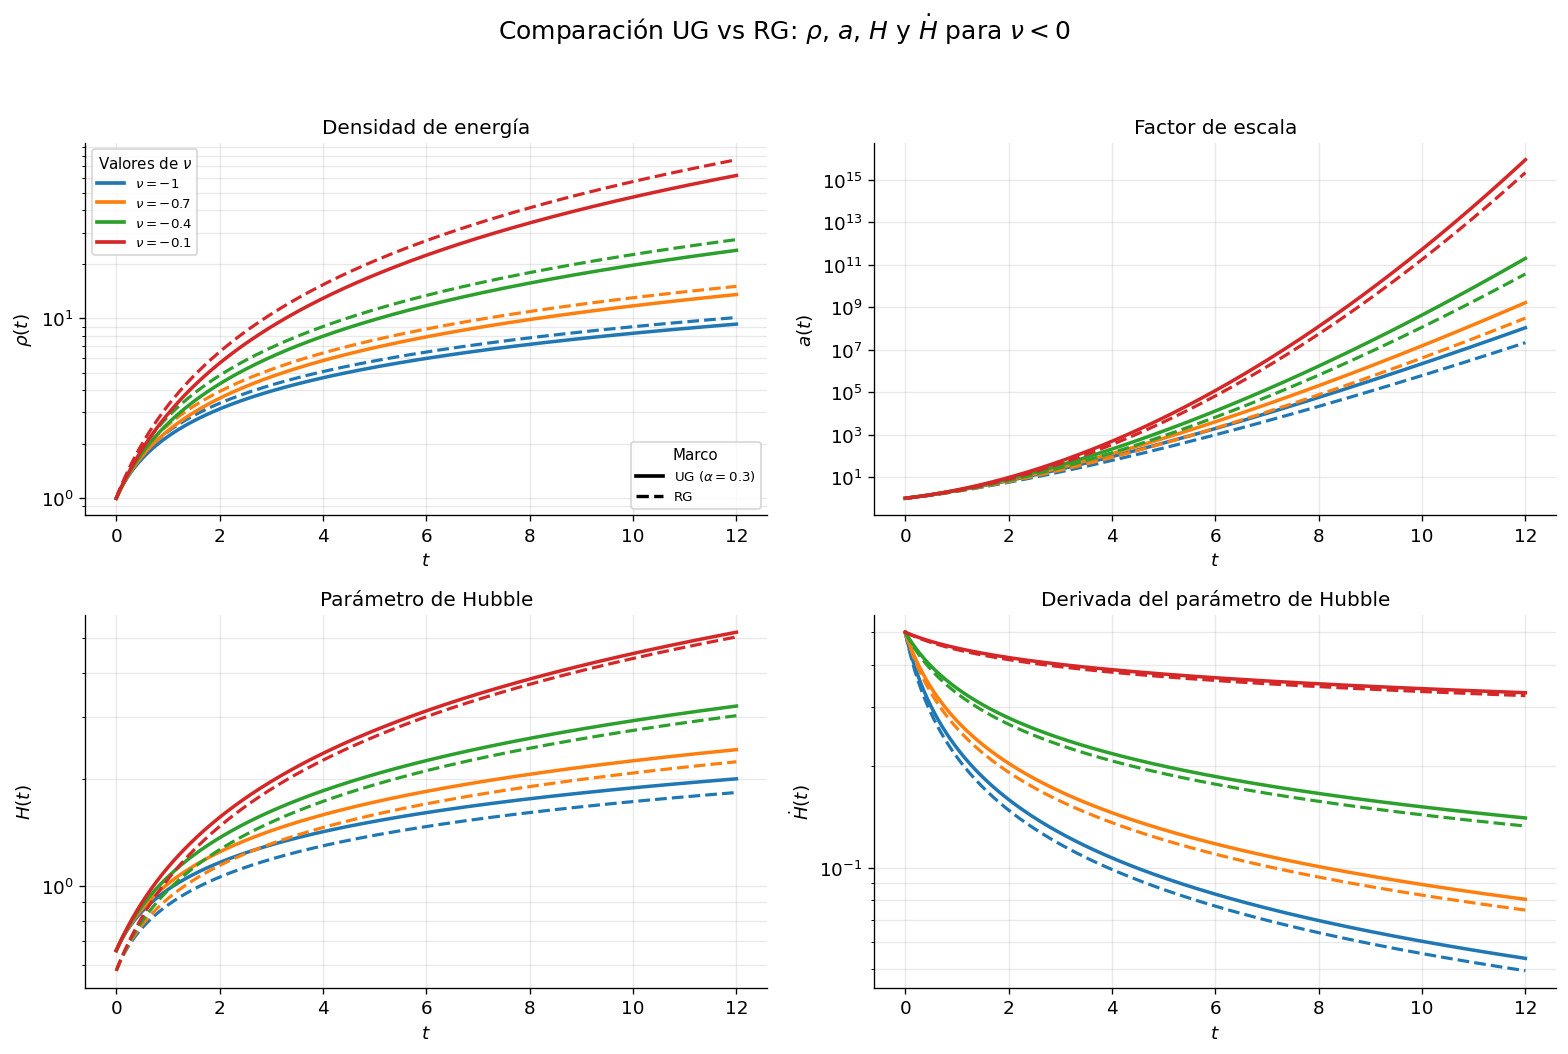

Figura guardada en: results/figures/ug_vs_rg/comparacion_ug_rg_nu_menor_0.pdf


In [6]:
plot_ug_vs_rg_interval(
    nu_values=[-1.0, -0.7, -0.4, -0.1],
    title=(
        r"Comparación UG vs RG: $\rho$, $a$, $H$ y $\dot H$ "
        r"para $\nu<0$"
    ),
    filename="comparacion_ug_rg_nu_menor_0.pdf",
    A=A,
    rho0=RHO0,
    a0=A0,
    t0=T0,
    alpha_ug=ALPHA_UG,
    t_max=12.0,
    a_log_scale=True,
)

## 5. Caso $(\nu=0)$

Este caso es un valor aislado y no un intervalo. Por ello se grafica un único par UG–RG.

Además,

$
\dot H=\frac{A}{2},
$

por lo que las curvas UG y RG de $(\dot H)$ coinciden exactamente.

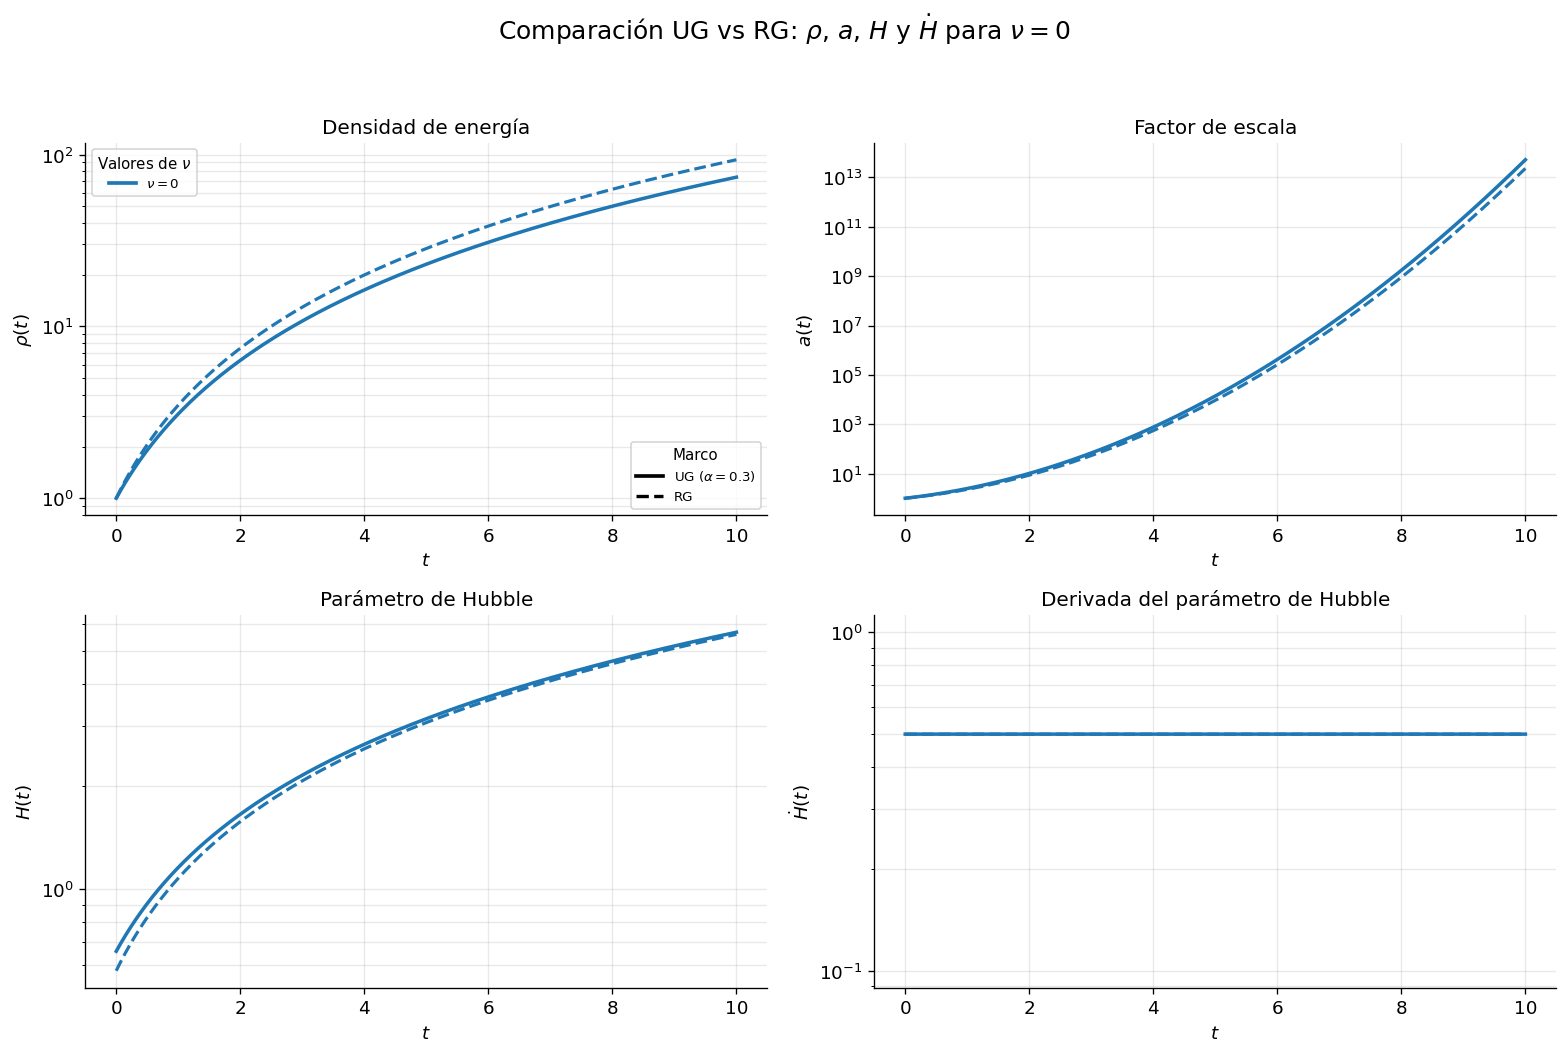

Figura guardada en: results/figures/ug_vs_rg/comparacion_ug_rg_nu_igual_0.pdf


In [7]:
plot_ug_vs_rg_interval(
    nu_values=[0.0],
    title=(
        r"Comparación UG vs RG: $\rho$, $a$, $H$ y $\dot H$ "
        r"para $\nu=0$"
    ),
    filename="comparacion_ug_rg_nu_igual_0.pdf",
    A=A,
    rho0=RHO0,
    a0=A0,
    t0=T0,
    alpha_ug=ALPHA_UG,
    t_max=10.0,
    a_log_scale=True,
)

## 6. Caso $(0<\nu<1/2)$

Se utilizan

$
\nu=0.1,\;0.2,\;0.3,\;0.4.
$

La divergencia de la densidad ocurre únicamente en el límite de tiempo infinito.

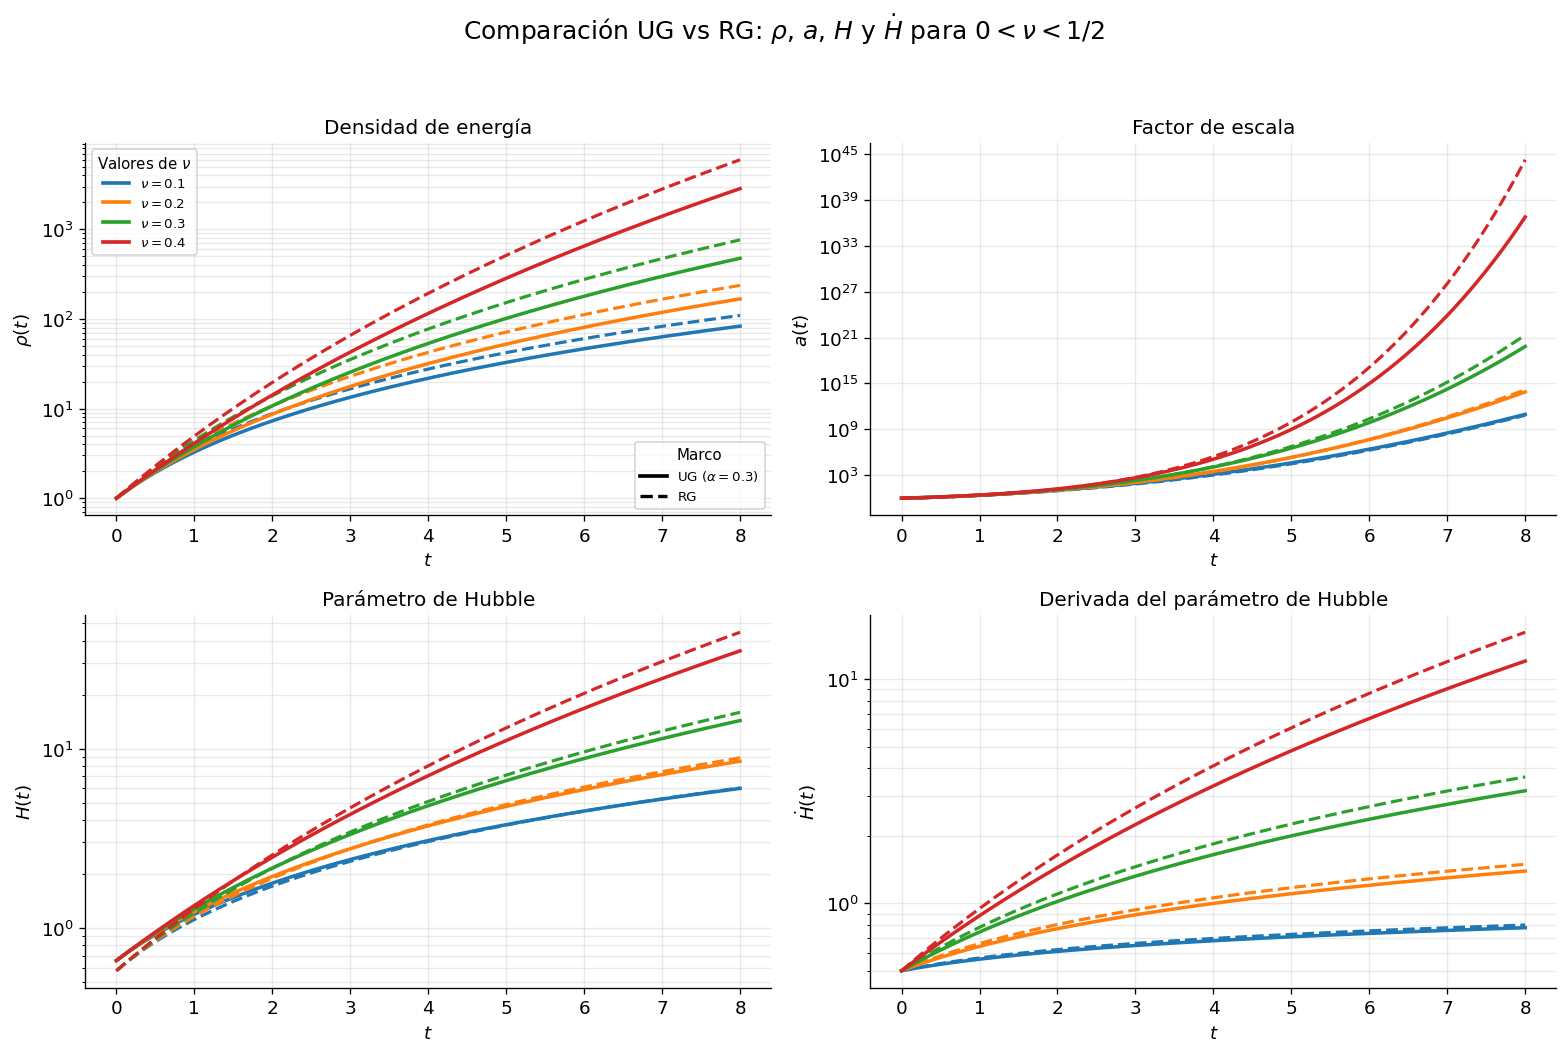

Figura guardada en: results/figures/ug_vs_rg/comparacion_ug_rg_0_menor_nu_menor_1_2.pdf


In [8]:
plot_ug_vs_rg_interval(
    nu_values=[0.1, 0.2, 0.3, 0.4],
    title=(
        r"Comparación UG vs RG: $\rho$, $a$, $H$ y $\dot H$ "
        r"para $0<\nu<1/2$"
    ),
    filename="comparacion_ug_rg_0_menor_nu_menor_1_2.pdf",
    A=A,
    rho0=RHO0,
    a0=A0,
    t0=T0,
    alpha_ug=ALPHA_UG,
    t_max=8.0,
    a_log_scale=True,
)

## 7. Caso $(1/2<\nu<1)$: Big Rip

Se utilizan

$
\nu=0.6,\;0.7,\;0.8,\;0.9.
$

En este intervalo la divergencia ocurre en tiempo finito y el factor de escala también diverge, por lo que corresponde a una singularidad tipo I (Big Rip).

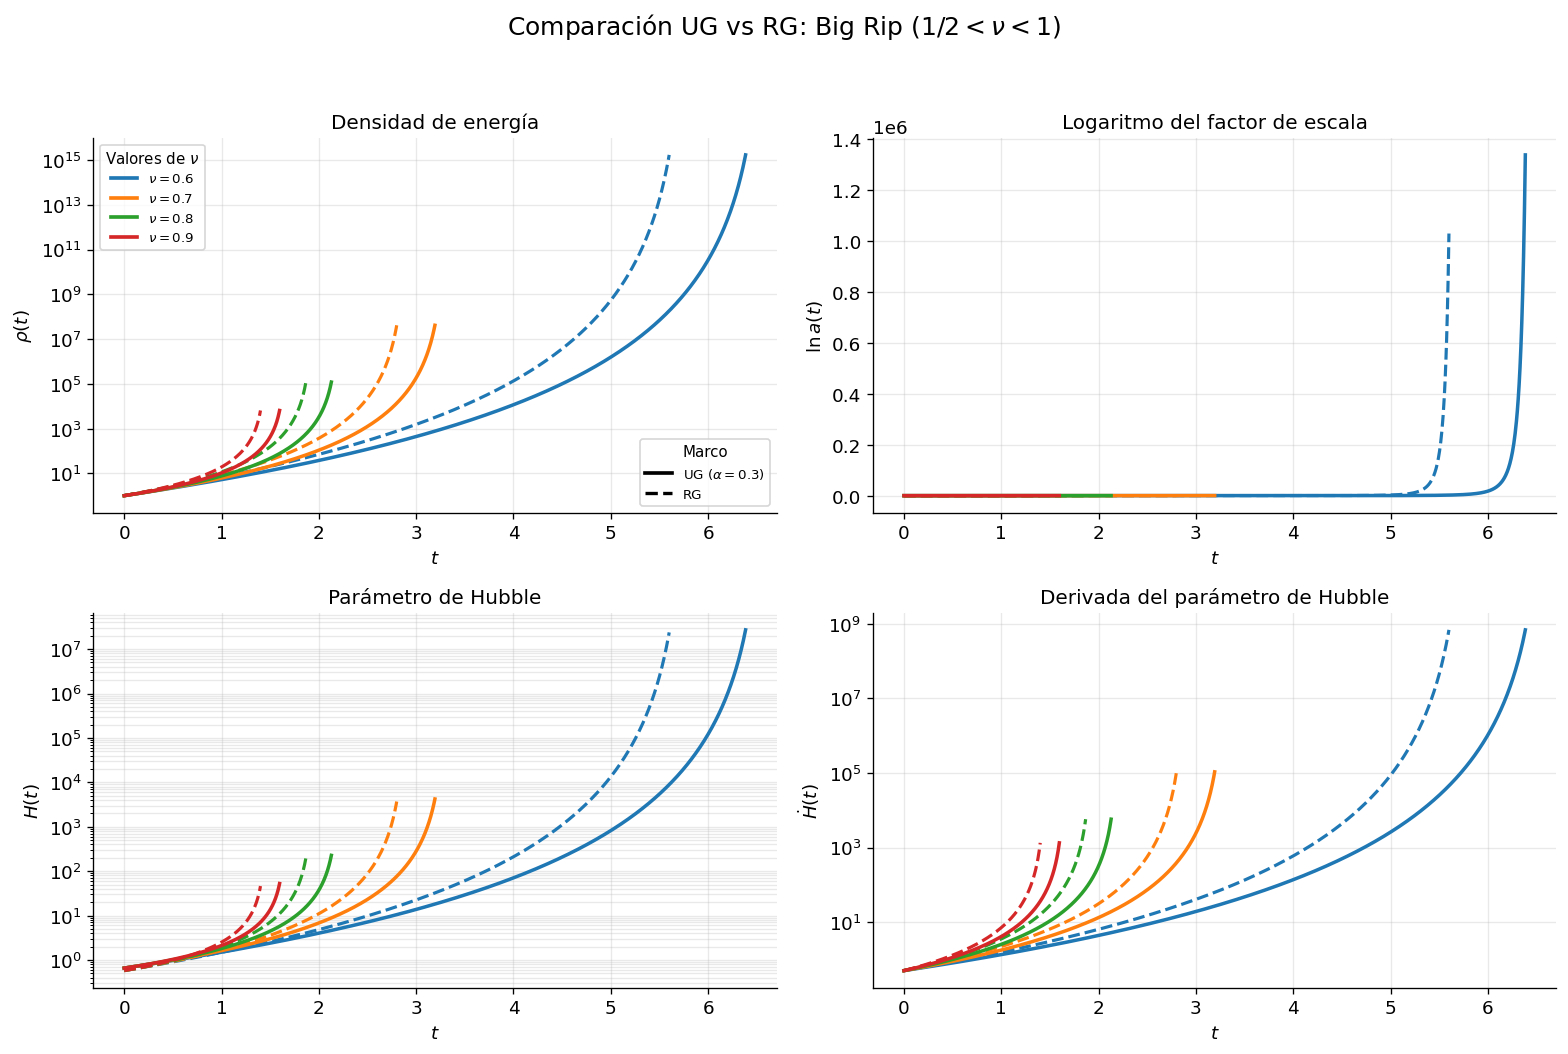

Figura guardada en: results/figures/ug_vs_rg/comparacion_ug_rg_big_rip.pdf


In [9]:
plot_ug_vs_rg_interval(
    nu_values=[0.6, 0.7, 0.8, 0.9],
    title=(
        r"Comparación UG vs RG: Big Rip "
        r"$(1/2<\nu<1)$"
    ),
    filename="comparacion_ug_rg_big_rip.pdf",
    A=A,
    rho0=RHO0,
    a0=A0,
    t0=T0,
    alpha_ug=ALPHA_UG,
    singular_fraction=0.97,
    a_log_scale=False,
    use_log_a=True,
)

## 8. Caso $(\nu>1)$: singularidad tipo III

Se utilizan

$
\nu=1.2,\;1.5,\;2.0,\;2.5.
$

En este régimen $(\rho)$, $(H)$ y $(\dot H)$ divergen en tiempo finito, mientras que el factor de escala se aproxima a un valor finito.

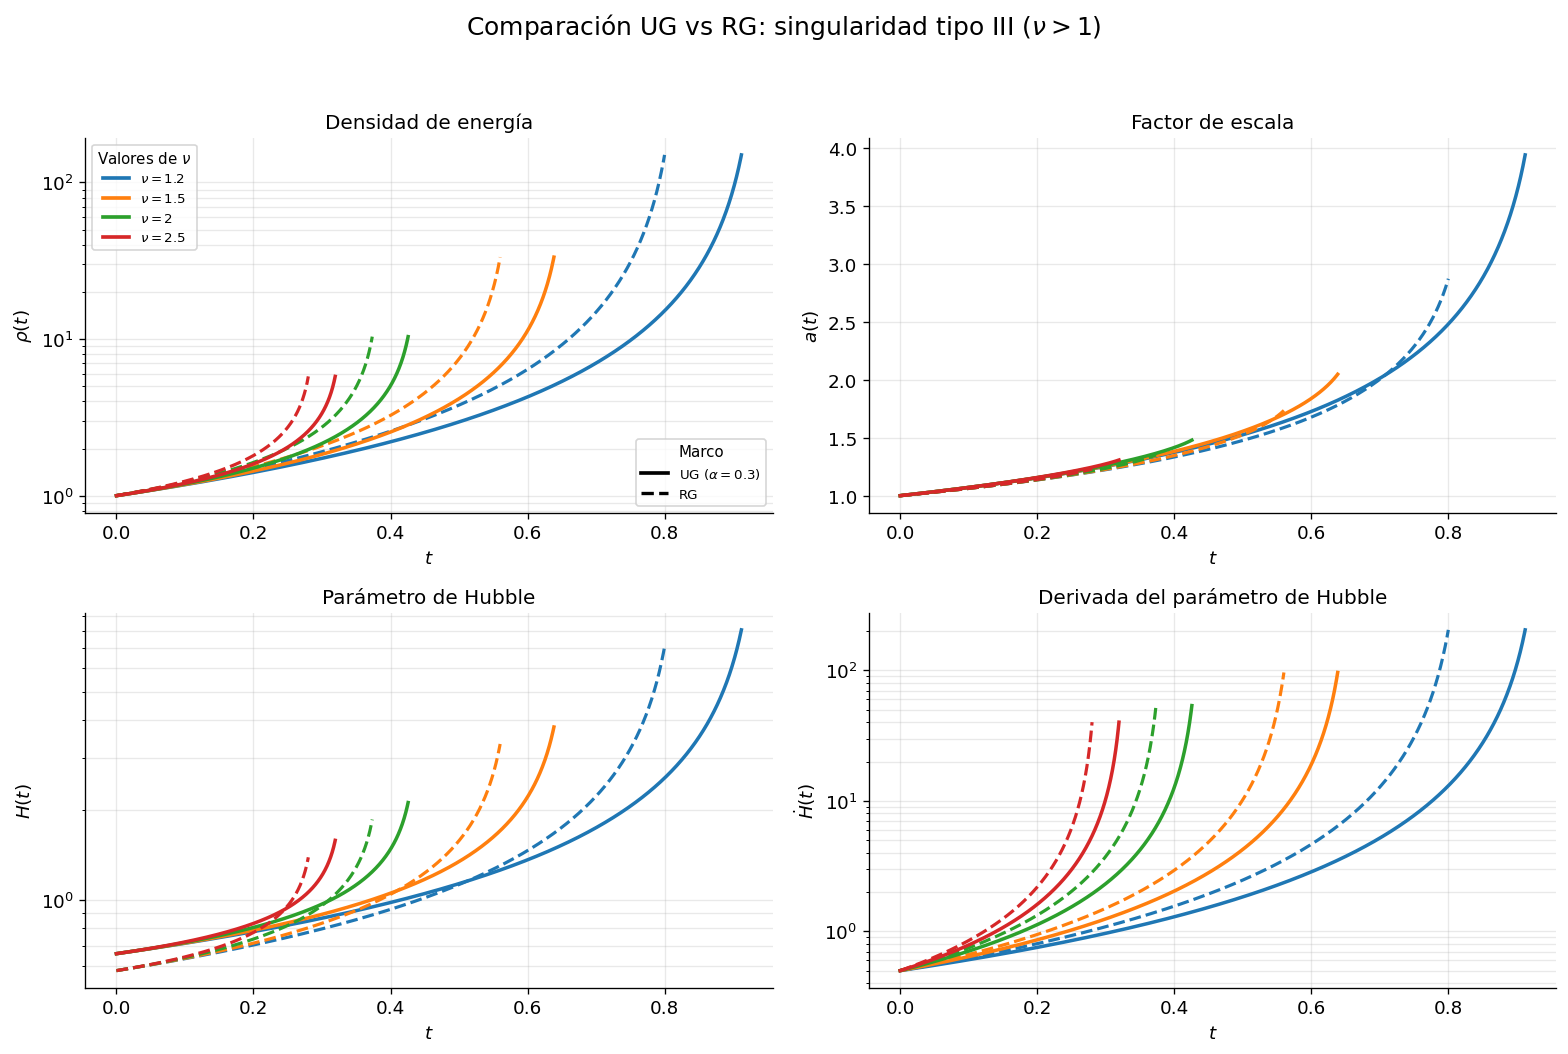

Figura guardada en: results/figures/ug_vs_rg/comparacion_ug_rg_tipo_iii.pdf


In [10]:
plot_ug_vs_rg_interval(
    nu_values=[1.2, 1.5, 2.0, 2.5],
    title=(
        r"Comparación UG vs RG: singularidad tipo III "
        r"$(\nu>1)$"
    ),
    filename="comparacion_ug_rg_tipo_iii.pdf",
    A=A,
    rho0=RHO0,
    a0=A0,
    t0=T0,
    alpha_ug=ALPHA_UG,
    singular_fraction=0.97,
    a_log_scale=False,
)

## 9. Comprobación de tiempos singulares

Esta tabla numérica permite comprobar, para los dos intervalos con singularidad de tiempo finito, que con $(\alpha_{\rm UG}>0)$

$
t_s^{\rm UG}>t_s^{\rm RG}.
$

No constituye una figura adicional; es una verificación de consistencia del notebook.

In [11]:
finite_nus = [0.6, 0.7, 0.8, 0.9, 1.2, 1.5, 2.0, 2.5]

print(f"{'nu':>6} | {'t_s RG':>12} | {'t_s UG':>12} | {'UG/RG':>9}")
print("-" * 49)

for nu in finite_nus:
    ts_rg = singular_time(A=A, nu=nu, alpha=0.0, rho0=RHO0, t0=T0)
    ts_ug = singular_time(A=A, nu=nu, alpha=ALPHA_UG, rho0=RHO0, t0=T0)
    print(f"{nu:6.2f} | {ts_rg:12.6f} | {ts_ug:12.6f} | {ts_ug/ts_rg:9.6f}")

expected_ratio = np.sqrt(1.0 + ALPHA_UG)
print("\nRazón teórica sqrt(1+alpha_UG) =", expected_ratio)

    nu |       t_s RG |       t_s UG |     UG/RG
-------------------------------------------------
  0.60 |     5.773503 |     6.582806 |  1.140175
  0.70 |     2.886751 |     3.291403 |  1.140175
  0.80 |     1.924501 |     2.194269 |  1.140175
  0.90 |     1.443376 |     1.645701 |  1.140175
  1.20 |     0.824786 |     0.940401 |  1.140175
  1.50 |     0.577350 |     0.658281 |  1.140175
  2.00 |     0.384900 |     0.438854 |  1.140175
  2.50 |     0.288675 |     0.329140 |  1.140175

Razón teórica sqrt(1+alpha_UG) = 1.140175425099138


## Archivos generados

Las cinco figuras vectoriales se guardan en
`results/figures/ug_vs_rg/`.
